In [ ]:
# Resolve paths when launched from either the repository or notebooks folder.
from pathlib import Path
import os
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pyproject.toml").is_file() and (p / "cyberhull").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch this notebook from the CyberHull repository.")
os.chdir(PROJECT_ROOT)
Path("results/generated").mkdir(parents=True, exist_ok=True)


In [3]:
#@title Install dependencies (Colab)
# !pip -q install tldextract networkx python-slugify scipy pandas numpy matplotlib wordcloud
%pip install tldextract networkx python-slugify scipy pandas numpy matplotlib wordcloud


   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.9 MB 696.9 kB/s eta 0:00:14
   --- ------------------------------------ 0.8/9.9 MB 877.3 kB/s eta 0:00:11
   ---- ----------------------------------- 1.0/9.9 MB 915.2 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.9 MB 915.2 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.9 MB 774.9 kB/s eta 0:00:12
   ----- ---------------------------------- 1.3/9.9 MB 774.9 kB/s eta 0:00:12
   ----- ---------------------------------- 1.3/9.9 MB 774.9 kB/s eta 0:00:12
   ------ ------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
#@title Configuration (paths, toggles, approximations)
from dataclasses import dataclass
from typing import Optional

@dataclass
class Config:
    # json_path: Optional[str] = "E:\Convex Hull - New Algorithm\final_merged.json"  # <— your file
    json_path: Optional[str] = r"C:\Users\anike\OneDrive\Desktop\IEEE_INDICON_NOTES-main\IEEE_INDICON_NOTES-main\final_merged.json"
    pasted_json_text: str = ""  # leave empty since using a file

    # Graph / centrality
    build_graph: bool = True
    use_betweenness_approx: bool = True
    betweenness_k_samples: int = 600     # tune for speed/accuracy
    compute_closeness: bool = False      # off by default for larger graphs

    # Output
    out_dir: str = "results/generated/collection"
    figures_dpi: int = 200

CFG = Config()
CFG


Config(json_path='C:\\Users\\anike\\OneDrive\\Desktop\\IEEE_INDICON_NOTES-main\\IEEE_INDICON_NOTES-main\\final_merged.json', pasted_json_text='', build_graph=True, use_betweenness_approx=True, betweenness_k_samples=600, compute_closeness=False, out_dir='/entro_results', figures_dpi=200)

In [2]:
import os

# Automatically find the file in the exact same folder as this notebook
CFG.json_path = os.path.abspath("final_merged.json")

print(f"I am looking for the file here: {CFG.json_path}")
print(f"Does the file exist? {os.path.exists(CFG.json_path)}")

I am looking for the file here: e:\Convex Hull - New Algorithm\final_merged.json
Does the file exist? True


In [3]:
#@title Load JSON records (robust; fixes trailing commas)
import os, re, json
from typing import List, Dict, Any
import pandas as pd
import numpy as np

os.makedirs(CFG.out_dir, exist_ok=True)

def _try_load_json_str(s: str):
    s = s.strip()
    # Try strict list
    if s.startswith("["):
        try:
            return json.loads(s)
        except:
            pass
    # Try "comma-separated" objects (wrap into [])
    if s.startswith("{") and s.endswith("}"):
        parts = re.split(r'}\s*,\s*{', s)
        if len(parts) > 1:
            s_fixed = "[" + s + "]"
            s_fixed = re.sub(r",\s*]", "]", s_fixed)
            try:
                return json.loads(s_fixed)
            except:
                pass
    # Try JSONL
    recs = []
    ok = False
    for line in s.splitlines():
        line = line.strip().rstrip(",")
        if not line:
            continue
        try:
            recs.append(json.loads(line))
            ok = True
        except:
            pass
    if ok:
        return recs
    return None

def load_json_records() -> List[Dict[str, Any]]:
    if CFG.pasted_json_text.strip():
        data = _try_load_json_str(CFG.pasted_json_text)
        if data is None or not isinstance(data, list):
            raise ValueError("Unable to parse pasted_json_text as list/JSONL.")
        return data

    if CFG.json_path is None or not os.path.exists(CFG.json_path):
        raise FileNotFoundError("Set CFG.json_path to /final_merged.json.")
    with open(CFG.json_path, "r", encoding="utf-8") as f:
        raw = f.read()

    # Fix trailing commas in objects/arrays
    raw_fixed = re.sub(r",\s*}", "}", raw)
    raw_fixed = re.sub(r",\s*]", "]", raw_fixed)

    data = _try_load_json_str(raw_fixed)
    if data is None or not isinstance(data, list):
        raise ValueError("Could not parse final_merged.json — ensure it’s a list/JSONL.")
    return data

records = load_json_records()
print(f"Loaded {len(records)} main records.")
if records:
    print("Sample keys:", sorted(list(records[0].keys())))


Loaded 1674 main records.
Sample keys: ['combined_entropy', 'external_links', 'internal_pages', 'keyword_scores', 'main_content_file', 'main_entropy', 'main_url', 'status']


In [4]:
#@title Normalize status and sanity checks
required_keys = {"main_url", "status"}
missing = sum(1 for r in records if not required_keys.issubset(r.keys()))
if missing:
    print(f"Warning: {missing} records missing one of {required_keys} — kept as 'Unknown' class.")

def normalize_status(x):
    if x == 1: return 1
    if x == -1: return -1
    return 0  # Unknown

for r in records:
    r["status"] = normalize_status(r.get("status", 0))


In [1]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
#@title Helper utils
import tldextract
from urllib.parse import urlparse
from typing import Any
from tqdm import tqdm
tqdm.pandas()

def registrable_domain(url: str) -> str:
    try:
        p = urlparse(url)
        host = p.netloc or p.path
        ext = tldextract.extract(host)
        if not ext.domain:
            return (host or "").lower()
        return f"{ext.domain}.{ext.suffix}".lower() if ext.suffix else ext.domain.lower()
    except Exception:
        return ""

def safe_get(d: dict, key: str, default=None):
    v = d.get(key, default)
    return v if v is not None else default

def winsorize_series(s: pd.Series, lower=0.01, upper=0.99) -> pd.Series:
    if s.isna().all(): return s
    lo = s.quantile(lower)
    hi = s.quantile(upper)
    return s.clip(lower=lo, upper=hi)


In [11]:
%pip install pyarrow

   ---------------------------------------- 0.0/28.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/28.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/28.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/28.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/28.2 MB ? eta -:--:--
    --------------------------------------- 0.5/28.2 MB 1.5 MB/s eta 0:00:19
   - -------------------------------------- 0.8/28.2 MB 1.3 MB/s eta 0:00:21
   - -------------------------------------- 1.3/28.2 MB 1.3 MB/s eta 0:00:21
   -- ------------------------------------- 1.6/28.2 MB 1.3 MB/s eta 0:00:21
   -- ------------------------------------- 1.6/28.2 MB 1.3 MB/s eta 0:00:21
   -- ------------------------------------- 1.8/28.2 MB 1.2 MB/s eta 0:00:23
   -- ------------------------------------- 2.1/28.2 MB 1.1 MB/s eta 0:00:24
   -- ------------------------------------- 2.1/28.2 MB 1.1 MB/s eta 0:00:24
   -- ----------------------------


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
#@title Build DataFrames (main, keywords, edges) and save
rows, kw_rows, edge_rows = [], [], []

for rec in records:
    main_url = safe_get(rec, "main_url", "")
    status = safe_get(rec, "status", 0)
    internal_pages = safe_get(rec, "internal_pages", []) or []
    external_links = safe_get(rec, "external_links", []) or []
    main_entropy = safe_get(rec, "main_entropy", np.nan)
    combined_entropy = safe_get(rec, "combined_entropy", np.nan)
    keyword_scores = safe_get(rec, "keyword_scores", {}) or {}

    dom_main = registrable_domain(main_url)
    n_internal = len(internal_pages)
    n_external = len(external_links)

    # internal entropy stats
    internal_entropies = []
    for p in internal_pages:
        if isinstance(p, dict):
            e = safe_get(p, "entropy", np.nan)
            if isinstance(e, (int, float)):
                internal_entropies.append(e)
    avg_internal_entropy = float(np.mean(internal_entropies)) if internal_entropies else np.nan
    max_internal_entropy = float(np.max(internal_entropies)) if internal_entropies else np.nan
    min_internal_entropy = float(np.min(internal_entropies)) if internal_entropies else np.nan

    rows.append({
        "main_url": main_url,
        "main_domain": dom_main,
        "status": status,
        "n_internal_pages": n_internal,
        "n_external_links": n_external,
        "main_entropy": main_entropy,
        "combined_entropy": combined_entropy,
        "avg_internal_entropy": avg_internal_entropy,
        "max_internal_entropy": max_internal_entropy,
        "min_internal_entropy": min_internal_entropy,
        "has_keywords": 1 if keyword_scores else 0,
    })

    for k, v in keyword_scores.items():
        kw_rows.append({
            "main_url": main_url,
            "main_domain": dom_main,
            "status": status,
            "keyword": str(k),
            "score": float(v),
        })

    for ext_url in external_links:
        d_ext = registrable_domain(str(ext_url))
        if d_ext and d_ext != dom_main:
            edge_rows.append({"src_domain": dom_main, "dst_domain": d_ext, "status": status})

df = pd.DataFrame(rows)
df_kw = pd.DataFrame(kw_rows)
df_edges = pd.DataFrame(edge_rows)

print("df shape:", df.shape); display(df.head(2))
print("df_kw shape:", df_kw.shape); display(df_kw.head(2))
print("df_edges shape:", df_edges.shape); display(df_edges.head(2))

df.to_csv(f"{CFG.out_dir}/main_records.csv", index=False)
df_kw.to_csv(f"{CFG.out_dir}/keyword_scores_long.csv", index=False)
df_edges.to_csv(f"{CFG.out_dir}/external_edges.csv", index=False)

# df.to_parquet(f"{CFG.out_dir}/main_records.parquet", index=False)
# df_kw.to_parquet(f"{CFG.out_dir}/keyword_scores_long.parquet", index=False)
# df_edges.to_parquet(f"{CFG.out_dir}/external_edges.parquet", index=False)


df shape: (1674, 11)


,main_url,main_domain,status,n_internal_pages,n_external_links,main_entropy,combined_entropy,avg_internal_entropy,max_internal_entropy,min_internal_entropy,has_keywords
0,http://www.crestonwood.com/router.php,crestonwood.com,1,0,0,0.0,0.0,NaN,NaN,NaN,0
1,http://shadetreetechnology.com/v4/validation/a...,shadetreetechnology.com,-1,0,0,0.0,0.0,NaN,NaN,NaN,0


df_kw shape: (36575, 5)


,main_url,main_domain,status,keyword,score
0,http://rgipt.ac.in,rgipt.ac.in,1,00,0.0
1,http://rgipt.ac.in,rgipt.ac.in,1,000,0.0


df_edges shape: (14751, 3)


,src_domain,dst_domain,status
0,rgipt.ac.in,linkedin.com,1
1,rgipt.ac.in,facebook.com,1


In [7]:
#@title Dataset summaries (paper table)
def cls_name(x): return {1:"Legitimate", -1:"Phishing"}.get(x, "Unknown")
df["class"] = df["status"].apply(cls_name)

summary_counts = (
    df.groupby("class")
      .agg(n=("main_url","count"),
           mean_internal=("n_internal_pages","mean"),
           mean_external=("n_external_links","mean"),
           mean_main_entropy=("main_entropy","mean"),
           mean_combined_entropy=("combined_entropy","mean"),
           mean_avg_internal_entropy=("avg_internal_entropy","mean"))
      .reset_index()
)
display(summary_counts)

latex_counts = summary_counts.round(3).to_latex(index=False, caption="Dataset Summary by Class", label="tab:dataset_summary")
with open(f"{CFG.out_dir}/table_dataset_summary.tex","w") as f:
    f.write(latex_counts)

summary_counts.to_csv(f"{CFG.out_dir}/table_dataset_summary.csv", index=False)


,class,n,mean_internal,mean_external,mean_main_entropy,mean_combined_entropy,mean_avg_internal_entropy
0,Legitimate,204,76.691176,10.637255,0.026265,0.012791,0.029296
1,Phishing,196,1.178571,0.698980,0.018777,0.016247,0.060988
2,Unknown,1274,49.484301,9.768446,4.487903,4.797751,5.206479


Saved plots to: /entro_results


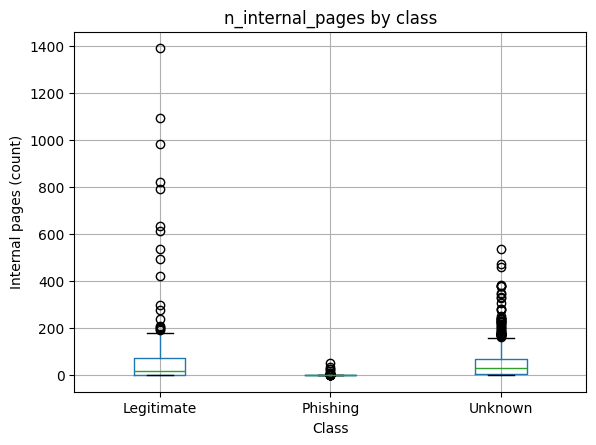

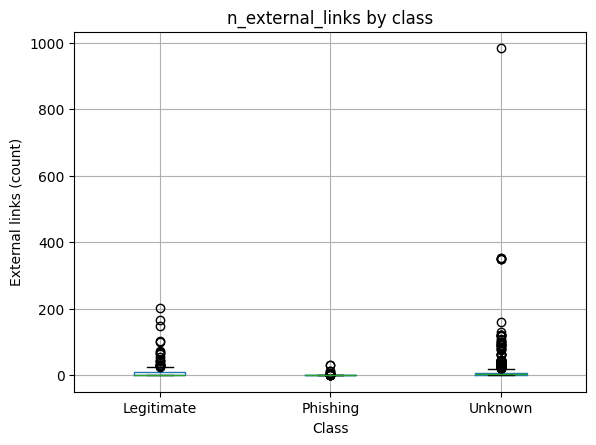

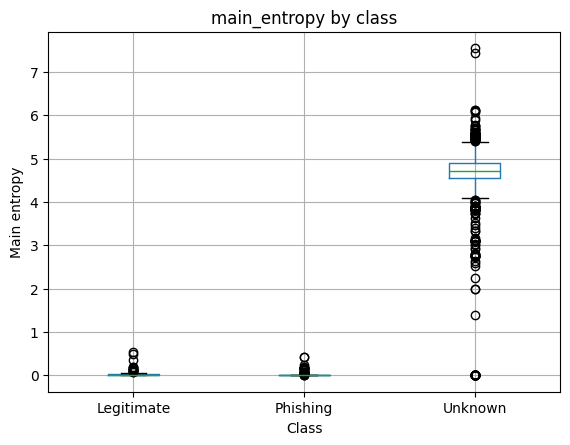

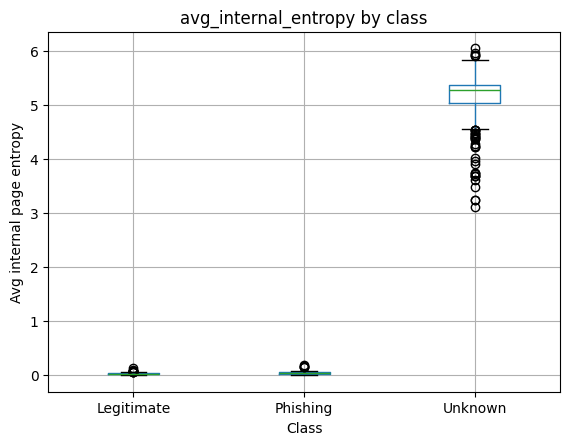

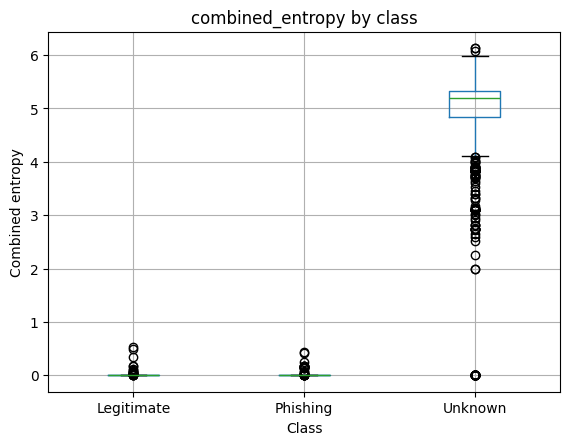

In [8]:
#@title Figures: Boxplots, Histograms, ECDFs (one figure per chart)
import matplotlib.pyplot as plt
import os

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(CFG.out_dir, name), dpi=CFG.figures_dpi, bbox_inches="tight")
    plt.close(fig)

def ecdf(x):
    x = np.sort(np.array(x))
    y = np.arange(1, len(x)+1)/len(x)
    return x, y

def boxplot_feature(feature, ylabel, fname):
    sub = df.dropna(subset=[feature])
    if sub.empty: return
    fig = plt.figure()
    sub.boxplot(column=feature, by="class")
    plt.title(f"{feature} by class"); plt.suptitle("")
    plt.xlabel("Class"); plt.ylabel(ylabel)
    save_fig(fig, fname)

def hist_feature(feature, bins, fname):
    sub = df.dropna(subset=[feature])
    if sub.empty: return
    fig = plt.figure()
    for c, g in sub.groupby("class"):
        plt.hist(g[feature], bins=bins, alpha=0.5, label=c)
    plt.xlabel(feature); plt.ylabel("Count")
    plt.title(f"{feature} distribution")
    plt.legend()
    save_fig(fig, fname)

def ecdf_plot(feature, fname):
    sub = df.dropna(subset=[feature])
    if sub.empty: return
    fig = plt.figure()
    for c, g in sub.groupby("class"):
        x, y = ecdf(g[feature])
        plt.plot(x, y, label=c, drawstyle="steps-post")
    plt.xlabel(feature); plt.ylabel("ECDF")
    plt.title(f"ECDF of {feature}")
    plt.legend()
    save_fig(fig, fname)

for feat, lbl in [
    ("n_internal_pages", "Internal pages (count)"),
    ("n_external_links", "External links (count)"),
    ("main_entropy", "Main entropy"),
    ("avg_internal_entropy", "Avg internal page entropy"),
    ("combined_entropy", "Combined entropy"),
]:
    boxplot_feature(feat, lbl, f"box_{feat}.png")
    hist_feature(feat, bins=30, fname=f"hist_{feat}.png")
    ecdf_plot(feat, f"ecdf_{feat}.png")

print("Saved plots to:", CFG.out_dir)


Cell 9 — Significance tests (Mann-Whitney U) + Cliff’s delta

In [9]:
#@title Nonparametric tests & effect sizes
from scipy.stats import mannwhitneyu

def cliffs_delta(x, y):
    nx, ny = len(x), len(y)
    if nx == 0 or ny == 0:
        return float("nan")
    gt = sum(a > b for a in x for b in y)
    lt = sum(a < b for a in x for b in y)
    return (gt - lt) / (nx * ny)

metrics = ["n_internal_pages", "n_external_links", "main_entropy", "avg_internal_entropy", "combined_entropy"]
rows_stats = []

for m in metrics:
    a = df[df["class"]=="Legitimate"][m].dropna().values
    b = df[df["class"]=="Phishing"][m].dropna().values
    if len(a) > 0 and len(b) > 0:
        u, p = mannwhitneyu(a, b, alternative="two-sided")
        cd = cliffs_delta(a, b)
        rows_stats.append({"metric": m, "mw_U": u, "p_value": p, "cliffs_delta": cd,
                           "mean_legit": a.mean(), "mean_phish": b.mean()})
stats_df = pd.DataFrame(rows_stats)
display(stats_df)

stats_df.round(6).to_csv(f"{CFG.out_dir}/stats_mw_cliff.csv", index=False)
latex_stats = stats_df.round(4).to_latex(index=False, caption="Nonparametric Tests & Effect Sizes", label="tab:stats")
with open(f"{CFG.out_dir}/table_stats.tex","w") as f:
    f.write(latex_stats)


,metric,mw_U,p_value,cliffs_delta,mean_legit,mean_phish
0,n_internal_pages,30456.5,7.206205e-26,0.523434,76.691176,1.178571
1,n_external_links,29711.0,2.807893e-23,0.486144,10.637255,0.698980
2,main_entropy,28262.0,1.010700e-15,0.413665,0.026265,0.018777
3,avg_internal_entropy,1002.0,9.212603e-03,-0.332000,0.029296,0.060988
4,combined_entropy,27786.0,2.640551e-14,0.389856,0.012791,0.016247


Cell 10 — Keyword signals (robust: ensure class)

In [10]:
#@title Keyword analysis (robust: ensure `class`, handle missing cols)
import matplotlib.pyplot as plt

def ensure_kw_class(df_kw: pd.DataFrame, df_main: pd.DataFrame) -> pd.DataFrame:
    """Ensure df_kw has a 'class' column derived from status or joined from df_main."""
    if df_kw.empty:
        return df_kw
    if "class" in df_kw.columns:
        df_kw["class"] = df_kw["class"].fillna("Unknown")
        return df_kw
    # Try from status
    if "status" in df_kw.columns:
        status_to_class = {1: "Legitimate", -1: "Phishing"}
        df_kw["class"] = df_kw["status"].map(status_to_class).fillna("Unknown")
        return df_kw
    # Try joining from main df
    if "main_url" in df_kw.columns and "class" in df_main.columns:
        df_kw = df_kw.merge(df_main[["main_url", "class"]], on="main_url", how="left")
        df_kw["class"] = df_kw["class"].fillna("Unknown")
        return df_kw
    df_kw["class"] = "Unknown"
    return df_kw

if df_kw.empty:
    print("No keyword_scores present; skipping keyword analysis.")
else:
    needed = [c for c in ["keyword", "score", "main_url"] if c not in df_kw.columns]
    if needed:
        print(f"Keyword analysis skipped: df_kw missing columns: {needed}")
    else:
        df_kw = ensure_kw_class(df_kw, df)

        grp = (
            df_kw.groupby(["class","keyword"])
                 .agg(mean_score=("score","mean"),
                      docs=("main_url","nunique"))
                 .reset_index()
        )

        legit = grp[grp["class"]=="Legitimate"][["keyword","mean_score","docs"]] \
                .rename(columns={"mean_score":"legit_mean","docs":"legit_docs"})
        phish = grp[grp["class"]=="Phishing"][["keyword","mean_score","docs"]] \
                .rename(columns={"mean_score":"phish_mean","docs":"phish_docs"})

        kw = pd.merge(legit, phish, on="keyword", how="outer").fillna(0.0)
        kw["diff_legit_minus_phish"] = kw["legit_mean"] - kw["phish_mean"]
        kw["diff_phish_minus_legit"] = -kw["diff_legit_minus_phish"]

        top_legit = kw.sort_values("diff_legit_minus_phish", ascending=False).head(20)
        top_phish = kw.sort_values("diff_phish_minus_legit", ascending=False).head(20)

        display(top_legit.head(10))
        display(top_phish.head(10))

        fig = plt.figure()
        plt.barh(top_legit["keyword"], top_legit["diff_legit_minus_phish"])
        plt.gca().invert_yaxis()
        plt.title("Top Legit-leaning Keywords (mean score difference)")
        plt.xlabel("Mean score difference")
        fig.tight_layout()
        fig.savefig(f"{CFG.out_dir}/kw_top_legit.png", dpi=CFG.figures_dpi, bbox_inches="tight"); plt.close(fig)

        fig = plt.figure()
        plt.barh(top_phish["keyword"], top_phish["diff_phish_minus_legit"])
        plt.gca().invert_yaxis()
        plt.title("Top Phish-leaning Keywords (mean score difference)")
        plt.xlabel("Mean score difference")
        fig.tight_layout()
        fig.savefig(f"{CFG.out_dir}/kw_top_phish.png", dpi=CFG.figures_dpi, bbox_inches="tight"); plt.close(fig)

        top_legit.to_csv(f"{CFG.out_dir}/keywords_top_legit.csv", index=False)
        top_phish.to_csv(f"{CFG.out_dir}/keywords_top_phish.csv", index=False)
        kw.to_csv(f"{CFG.out_dir}/keywords_diff_full.csv", index=False)


,keyword,legit_mean,legit_docs,phish_mean,phish_docs,diff_legit_minus_phish,diff_phish_minus_legit
2726,imdbpro,1.000000,1.0,0.0,0.0,1.000000,-1.000000
4935,segmented,0.970658,1.0,0.0,0.0,0.970658,-0.970658
831,blackletter,0.864949,1.0,0.0,0.0,0.864949,-0.864949
2668,hyperlink,0.790870,1.0,0.0,0.0,0.790870,-0.790870
5403,tabloid,0.765035,2.0,0.0,0.0,0.765035,-0.765035
5461,techteach,0.731216,1.0,0.0,0.0,0.731216,-0.731216
2343,gateway,0.731123,2.0,0.0,0.0,0.731123,-0.731123
728,barbo,0.707107,1.0,0.0,0.0,0.707107,-0.707107
2520,haciserif,0.707107,1.0,0.0,0.0,0.707107,-0.707107
5029,shot,0.699303,1.0,0.0,0.0,0.699303,-0.699303


,keyword,legit_mean,legit_docs,phish_mean,phish_docs,diff_legit_minus_phish,diff_phish_minus_legit
393,aguarde,0.000000,0.0,1.000000,1.0,-1.000000,1.000000
900,box,0.022464,5.0,1.000000,1.0,-0.977536,0.977536
2757,index,0.027507,4.0,1.000000,1.0,-0.972493,0.972493
6117,winger,0.000000,0.0,0.710826,1.0,-0.710826,0.710826
45,123formbuilder,0.000000,0.0,0.542982,1.0,-0.542982,0.542982
5964,vostbaddleschoi1973,0.000000,0.0,0.500000,1.0,-0.500000,0.500000
5352,suspended,0.000000,0.0,0.500000,1.0,-0.500000,0.500000
1782,drde,0.000000,0.0,0.500000,1.0,-0.500000,0.500000
3861,nã,0.000000,0.0,0.493417,1.0,-0.493417,0.493417
2713,ijikc,0.000000,0.0,0.485071,1.0,-0.485071,0.485071


{'n_nodes': 924, 'n_edges': 1477, 'density': 0.0017318362388784923, 'n_weak_components': 14, 'n_strong_components': 923, 'largest_WCC_size': 870, 'largest_SCC_size': 2}


,class,n,mean_out,mean_in,median_out,median_in
0,Legitimate,107,9.906542,0.560748,5.0,0.0
1,Phishing,17,3.588235,0.294118,2.0,0.0
2,Unknown,427,0.833724,1.587822,1.0,1.0
3,Unlabeled,373,0.000000,1.967828,0.0,1.0


Undirected eigenvector fallback failed: TypeError('Cannot use scipy.linalg.eig for sparse A with k >= N - 1. Use scipy.linalg.eig(A.toarray()) or reduce k.')


c:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\networkx\algorithms\centrality\eigenvector.py:352: RuntimeWarning: k >= N - 1 for N * N square matrix. Attempting to use scipy.linalg.eig instead.
  _, eigenvector = sp.sparse.linalg.eigs(


,domain,class,deg_c,bet_c,clo_c,pr_c,eig_c_ud
0,200ok.us,Unknown,0.002167,0.000000,NaN,0.000769,NaN
1,{'url',Unlabeled,0.368364,0.000000,NaN,0.244501,NaN
2,2345daohang.com,Legitimate,0.002167,0.000000,NaN,0.000739,NaN
3,4.cn,Unlabeled,0.001083,0.000000,NaN,0.001157,NaN
4,cashbackeasy.com,Unknown,0.002167,0.000002,NaN,0.000948,NaN


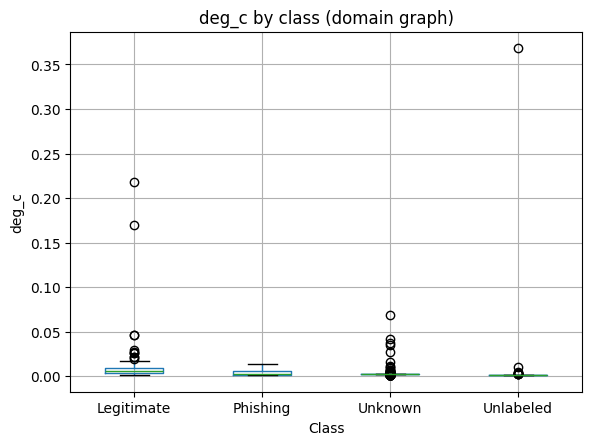

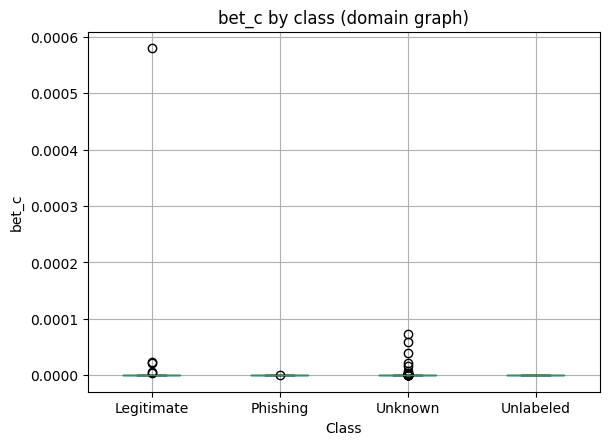

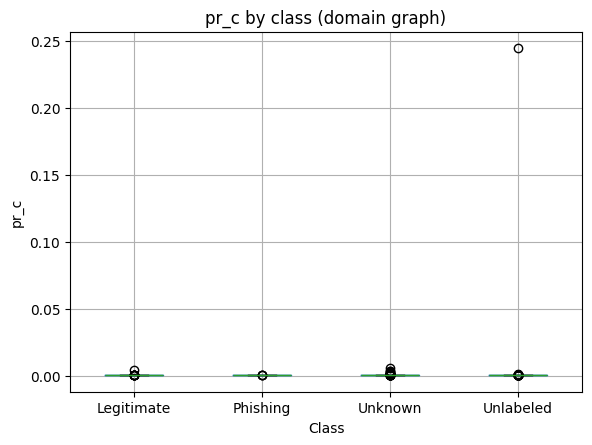

In [11]:
#@title Domain hyperlink graph & centrality metrics (robust to disconnected graphs)
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import os

graph_metrics = {}
centrality_rows = []

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(CFG.out_dir, name), dpi=CFG.figures_dpi, bbox_inches="tight")
    plt.close(fig)

if CFG.build_graph and not df_edges.empty:
    # 1) Build weighted directed graph
    edge_agg = (df_edges.groupby(["src_domain","dst_domain"])
                        .size()
                        .reset_index(name="weight"))

    G = nx.DiGraph()
    for _, r in edge_agg.iterrows():
        G.add_edge(r["src_domain"], r["dst_domain"], weight=int(r["weight"]))

    # 2) Majority label per domain from df (domains missing here become "Unlabeled")
    dom_labels = (df.groupby(["main_domain","class"]).size().reset_index(name="count"))
    maj = (dom_labels.sort_values(["main_domain","count"], ascending=[True, False])
                     .drop_duplicates("main_domain")[["main_domain","class"]])
    node_label_map = dict(zip(maj["main_domain"], maj["class"]))

    # 3) Graph summary metrics
    graph_metrics = {
        "n_nodes": G.number_of_nodes(),
        "n_edges": G.number_of_edges(),
        "density": nx.density(G),
        "n_weak_components": nx.number_weakly_connected_components(G),
        "n_strong_components": nx.number_strongly_connected_components(G),
        "largest_WCC_size": len(max(nx.weakly_connected_components(G), key=len)) if G.number_of_nodes() else 0,
        "largest_SCC_size": len(max(nx.strongly_connected_components(G), key=len)) if G.number_of_nodes() else 0,
    }
    print(graph_metrics)

    # 4) Degree (in/out) summaries by class
    out_deg = dict(G.out_degree())
    in_deg  = dict(G.in_degree())

    dom_deg = []
    for n in G.nodes():
        c = node_label_map.get(n, "Unlabeled")
        dom_deg.append({"domain": n, "class": c, "out_degree": out_deg.get(n,0), "in_degree": in_deg.get(n,0)})
    df_deg = pd.DataFrame(dom_deg)

    deg_summary = df_deg.groupby("class").agg(
        n=("domain","count"),
        mean_out=("out_degree","mean"),
        mean_in=("in_degree","mean"),
        median_out=("out_degree","median"),
        median_in=("in_degree","median"),
    ).reset_index()
    display(deg_summary)
    deg_summary.to_csv(f"{CFG.out_dir}/graph_degree_summary.csv", index=False)

    # 5) Centralities
    # 5a) Degree centrality (works on any graph)
    deg_cent = nx.degree_centrality(G)

    # 5b) Betweenness (sampled if configured)
    if CFG.use_betweenness_approx:
        bet_cent = nx.betweenness_centrality(G, k=min(CFG.betweenness_k_samples, max(1, G.number_of_nodes())), seed=42)
    else:
        bet_cent = nx.betweenness_centrality(G)

    # 5c) Closeness (optional; defined even on disconnected digraphs but small/zero on isolates)
    clo_cent = nx.closeness_centrality(G) if CFG.compute_closeness else {}

    # 5d) PageRank (robust on directed disconnected graphs)
    #     Uses edge weights; tweak alpha if desired
    pr_cent = nx.pagerank(G, alpha=0.85, weight="weight")

    # 5e) Optional: undirected eigenvector per WCC (component-wise), then merge
    #     This yields an "eigenvector-like" signal without raising on disconnectivity.
    eig_ud = {}
    try:
        UG = G.to_undirected()
        for comp in nx.connected_components(UG):
            H = UG.subgraph(comp)
            # Use numpy-based routine (fast & stable on connected undirected graphs)
            local = nx.eigenvector_centrality_numpy(H)
            eig_ud.update(local)
        eig_cent_ud = eig_ud  # alias
    except Exception as e:
        print("Undirected eigenvector fallback failed:", repr(e))
        eig_cent_ud = {}

    # 6) Assemble centrality dataframe
    for n in G.nodes():
        centrality_rows.append({
            "domain": n,
            "class": node_label_map.get(n, "Unlabeled"),
            "deg_c": deg_cent.get(n, np.nan),
            "bet_c": bet_cent.get(n, np.nan),
            "clo_c": clo_cent.get(n, np.nan) if clo_cent else np.nan,
            "pr_c":  pr_cent.get(n, np.nan),
            "eig_c_ud": eig_cent_ud.get(n, np.nan) if eig_cent_ud else np.nan,  # per-WCC undirected eigenvector
        })

    df_cent = pd.DataFrame(centrality_rows)
    df_cent.to_csv(f"{CFG.out_dir}/graph_centralities.csv", index=False)
    display(df_cent.head())

    # 7) Boxplots for available centralities (skip missing)
    def box_cent(col, title_suffix="(domain graph)"):
        if col not in df_cent.columns: return
        sub = df_cent[~df_cent[col].isna()]
        if sub.empty: return
        fig = plt.figure()
        sub.boxplot(column=col, by="class")
        plt.title(f"{col} by class {title_suffix}")
        plt.suptitle("")
        plt.xlabel("Class"); plt.ylabel(col)
        save_fig(fig, f"box_{col}.png")

    for c in ["deg_c","bet_c","clo_c","pr_c","eig_c_ud"]:
        box_cent(c)

else:
    print("Graph not built or no edges; skipping network centralities.")


Cell 12 — Extra analyses (domain aggs, outlinks, assortativity, components, communities, keyword coverage)

In [12]:
#@title Extra: per-domain tables, assortativity, components, communities, keyword coverage
import matplotlib.pyplot as plt
import networkx as nx

# Per-domain aggregates
dom_agg = (df.groupby(["main_domain","class"])
             .agg(n_urls=("main_url","nunique"),
                  med_internal=("n_internal_pages","median"),
                  med_external=("n_external_links","median"),
                  med_main_ent=("main_entropy","median"),
                  med_avg_int_ent=("avg_internal_entropy","median"))
             .reset_index())
dom_agg.to_csv(f"{CFG.out_dir}/domain_aggregates.csv", index=False)

# Top external domains by incoming links
if not df_edges.empty:
    ext_counts = (df_edges.groupby("dst_domain")
                            .size()
                            .reset_index(name="weight")
                            .sort_values("weight", ascending=False)
                            .head(30))
    fig = plt.figure()
    plt.barh(ext_counts["dst_domain"], ext_counts["weight"])
    plt.gca().invert_yaxis()
    plt.title("Top external domains by incoming links")
    plt.xlabel("Incoming links (count)")
    fig.tight_layout()
    fig.savefig(f"{CFG.out_dir}/top_external_domains.png", dpi=CFG.figures_dpi, bbox_inches="tight")
    plt.close(fig)

# Assortativity by class (robust to Unknown/Unlabeled)
if CFG.build_graph and not df_edges.empty and 'G' in globals():
    # 1) Ensure every node has a coarse-grained class label
    def normalize_label(lbl: str) -> str:
        if lbl == "Legitimate": return "Legitimate"
        if lbl == "Phishing": return "Phishing"
        return "Other"  # collapse Unknown/Unlabeled/None/etc.

    for n in G.nodes():
        raw = node_label_map.get(n, "Unlabeled")
        G.nodes[n]["label"] = normalize_label(raw)

    # 2) Integer encoding for attribute_assortativity_coefficient
    label_to_int = {"Legitimate": 0, "Phishing": 1, "Other": 2}
    for n in G.nodes():
        G.nodes[n]["label_int"] = label_to_int[G.nodes[n]["label"]]

    # 3) Assortativity
    assort = nx.attribute_assortativity_coefficient(G, "label_int")
    with open(f"{CFG.out_dir}/graph_assortativity.txt","w") as f:
        f.write(f"Attribute assortativity by class label: {assort:.4f}\n")
    print("Assortativity (class):", assort)

    # 4) Mixing matrix (edge counts between classes)
    classes = ["Legitimate", "Phishing", "Other"]
    idx = {c:i for i,c in enumerate(classes)}
    import numpy as np, pandas as pd, matplotlib.pyplot as plt, os

    M = np.zeros((len(classes), len(classes)), dtype=int)
    for u, v in G.edges():
        cu = G.nodes[u].get("label", "Other")
        cv = G.nodes[v].get("label", "Other")
        M[idx[cu], idx[cv]] += 1

    mix_df = pd.DataFrame(M, index=classes, columns=classes)
    mix_df.to_csv(f"{CFG.out_dir}/class_mixing_matrix.csv")
    display(mix_df)

    # 5) Plot heatmap (one figure, default colormap, no explicit colors)
    fig = plt.figure()
    plt.imshow(M, interpolation="nearest")
    plt.title("Class→Class Edge Mixing (counts)")
    plt.xlabel("Destination class")
    plt.ylabel("Source class")
    plt.xticks(range(len(classes)), classes, rotation=45, ha="right")
    plt.yticks(range(len(classes)), classes)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, str(M[i, j]), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(os.path.join(CFG.out_dir, "class_mixing_matrix.png"), dpi=CFG.figures_dpi, bbox_inches="tight")
    plt.close(fig)

# # Component size distributions
# if CFG.build_graph and not df_edges.empty and 'G' in globals() and G.number_of_nodes() > 0:
#     wcc_sizes = [len(c) for c in nx.weakly_connected_components(G)]
#     scc_sizes = [len(c) for c in nx.strongly_connected_components(G)]

#     fig = plt.figure()
#     plt.hist(wcc_sizes, bins=30)
#     plt.title("Weakly Connected Component Sizes")
#     plt.xlabel("Size"); plt.ylabel("Count")
#     fig.tight_layout()
#     fig.savefig(f"{CFG.out_dir}/hist_wcc_sizes.png", dpi=CFG.figures_dpi, bbox_inches="tight")
#     plt.close(fig)

#     fig = plt.figure()
#     plt.hist(scc_sizes, bins=30)
#     plt.title("Strongly Connected Component Sizes")
#     plt.xlabel("Size"); plt.ylabel("Count")
#     fig.tight_layout()
#     fig.savefig(f"{CFG.out_dir}/hist_scc_sizes.png", dpi=CFG.figures_dpi, bbox_inches="tight")
#     plt.close(fig)

# # Label propagation communities (undirected)
# if CFG.build_graph and not df_edges.empty and 'G' in globals():
#     UG = G.to_undirected()
#     comms = list(nx.algorithms.community.asyn_lpa_communities(UG, weight="weight", seed=42))
#     comm_sizes = sorted([len(c) for c in comms], reverse=True)
#     pd.Series(comm_sizes, name="community_size").to_csv(f"{CFG.out_dir}/label_propagation_comm_sizes.csv", index=False)

# # Keyword coverage
# kw_cov = df["has_keywords"].mean() if len(df) else 0.0
# with open(f"{CFG.out_dir}/keyword_coverage.txt","w") as f:
#     f.write(f"Proportion with non-empty keyword_scores: {kw_cov:.3f}\n")
# print("Keyword coverage:", round(kw_cov,3))


Assortativity (class): 0.025974146600022733


,Legitimate,Phishing,Other
Legitimate,57,5,998
Phishing,2,0,59
Other,1,0,355


In [13]:
#@title Robustness: Winsorized re-tests
from scipy.stats import mannwhitneyu

rob = df.copy()
for col in ["n_internal_pages","n_external_links","main_entropy","avg_internal_entropy","combined_entropy"]:
    if col in rob.columns:
        rob[col] = winsorize_series(rob[col])

rows_stats_rob = []
for m in ["n_internal_pages","n_external_links","main_entropy","avg_internal_entropy","combined_entropy"]:
    if m not in rob.columns: continue
    a = rob[rob["class"]=="Legitimate"][m].dropna().values
    b = rob[rob["class"]=="Phishing"][m].dropna().values
    if len(a) and len(b):
        u, p = mannwhitneyu(a, b, alternative="two-sided")
        rows_stats_rob.append({"metric": m, "mw_U": u, "p_value": p, "mean_legit": a.mean(), "mean_phish": b.mean()})
rob_stats = pd.DataFrame(rows_stats_rob)
display(rob_stats)
rob_stats.to_csv(f"{CFG.out_dir}/stats_mw_winsorized.csv", index=False)


,metric,mw_U,p_value,mean_legit,mean_phish
0,n_internal_pages,30456.5,7.197815e-26,56.051961,1.178571
1,n_external_links,29711.0,2.807819e-23,9.749559,0.698980
2,main_entropy,28262.0,1.010700e-15,0.026265,0.018777
3,avg_internal_entropy,1001.0,9.053668e-03,0.029483,0.061802
4,combined_entropy,27786.0,2.640551e-14,0.012791,0.016247


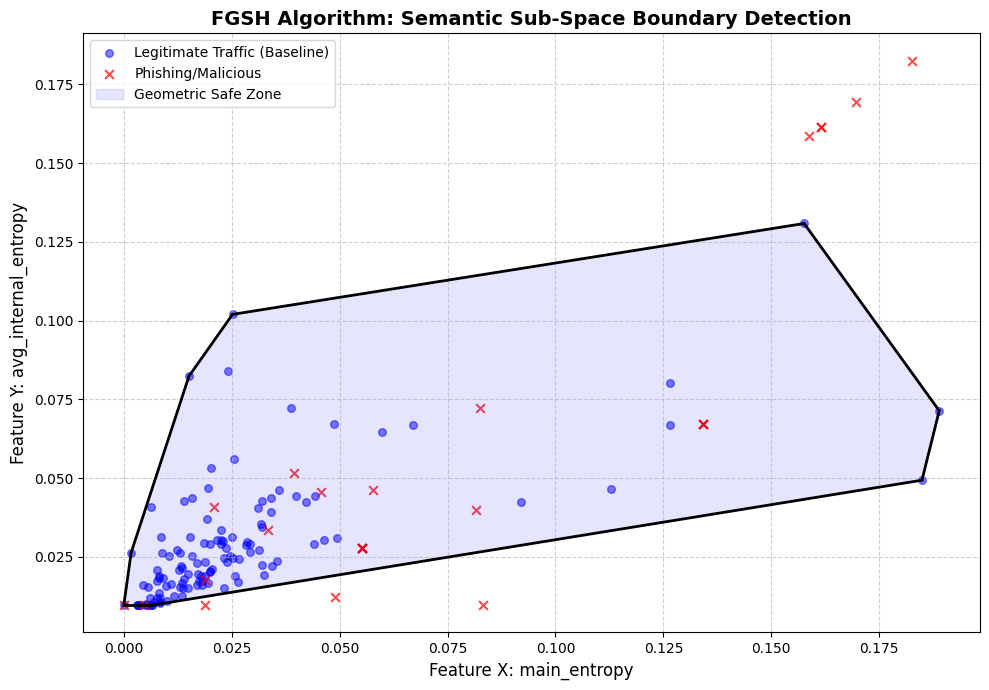

In [14]:
# Phase 1 & 2: Feature-Grouped Sub-Space Hulls (FGSH) Algorithm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, Delaunay

# 1. Define our Sub-Space features (Space B: Semantic Profile)
feature_x = "main_entropy"
feature_y = "avg_internal_entropy"

# 2. Extract and clean the data from the inherited 'rob' DataFrame
# We drop NaNs to ensure the geometry math doesn't crash
df_clean = rob.dropna(subset=[feature_x, feature_y, "class"]).copy()

# 3. Isolate the "Legitimate" baseline and "Phishing" test data
legit_data = df_clean[df_clean["class"] == "Legitimate"][[feature_x, feature_y]].values
phish_data = df_clean[df_clean["class"] == "Phishing"][[feature_x, feature_y]].values

# 4. Compute the Convex Hull purely on the Legitimate data
# This draws the minimal enclosing geometric boundary around normal traffic
hull = ConvexHull(legit_data)

# 5. Build the Visualization
plt.figure(figsize=(10, 7))

# Plot the legitimate points
plt.scatter(legit_data[:, 0], legit_data[:, 1], c='blue', alpha=0.5, label='Legitimate Traffic (Baseline)', s=30)

# Plot the malicious points
plt.scatter(phish_data[:, 0], phish_data[:, 1], c='red', alpha=0.7, marker='x', label='Phishing/Malicious', s=40)

# Draw the Convex Hull geometric boundary
for simplex in hull.simplices:
    plt.plot(legit_data[simplex, 0], legit_data[simplex, 1], 'k-', lw=2)

# Fill the safe zone for better visualization
plt.fill(legit_data[hull.vertices, 0], legit_data[hull.vertices, 1], color='blue', alpha=0.1, label='Geometric Safe Zone')

# Formatting the output to be clear and understandable
plt.title("FGSH Algorithm: Semantic Sub-Space Boundary Detection", fontsize=14, fontweight='bold')
plt.xlabel(f"Feature X: {feature_x}", fontsize=12)
plt.ylabel(f"Feature Y: {feature_y}", fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)

# Save and show the graphical output
plt.tight_layout()
plt.savefig("results/generated/FGSH_Semantic_Boundary.png", dpi=300)
plt.show()

In [16]:
#Phase 3: Multi-Space Inference (The Scoring Engine)
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull, Delaunay

# --- 1. Define Our Sub-Spaces ---
features_semantic = ["main_entropy", "avg_internal_entropy"]
features_struct = ["n_internal_pages", "n_external_links"]

df_eval = rob.dropna(subset=features_semantic + features_struct + ["class"]).copy()
legit_df = df_eval[df_eval["class"] == "Legitimate"]
phish_df = df_eval[df_eval["class"] == "Phishing"]

# --- THE FIX: The Core-Hull Boundary Optimizer ---
# We shrink the safe zone to remove "bagginess" by only building 
# the hull around the densest core of normal traffic.
def get_tight_delaunay(data_points, core_fraction=0.85):
    # 1. Find the geometric center (centroid)
    centroid = np.mean(data_points, axis=0)
    
    # 2. Calculate the distance of every point to the center
    distances = np.linalg.norm(data_points - centroid, axis=1)
    
    # 3. Find the distance threshold that captures our core fraction
    threshold = np.percentile(distances, core_fraction * 100)
    
    # 4. Filter out the sparse outer edge points
    core_points = data_points[distances <= threshold]
    
    # 5. Build the tight, highly-secure boundary
    return Delaunay(core_points)

# Build our new optimized, tight hulls
del_semantic = get_tight_delaunay(legit_df[features_semantic].values, core_fraction=0.85)
del_struct = get_tight_delaunay(legit_df[features_struct].values, core_fraction=0.85)

def in_hull(p, hull_delaunay):
    return hull_delaunay.find_simplex(p) >= 0

# --- 3. The Inference Engine ---
phish_semantic_points = phish_df[features_semantic].values
phish_struct_points = phish_df[features_struct].values

caught_by_semantic = 0
caught_by_struct = 0
caught_by_either = 0

for i in range(len(phish_df)):
    in_sem = in_hull(phish_semantic_points[i], del_semantic)
    in_str = in_hull(phish_struct_points[i], del_struct)
    
    if not in_sem: caught_by_semantic += 1
    if not in_str: caught_by_struct += 1
    if not in_sem or not in_str: caught_by_either += 1

# --- 4. Output The Optimized Results ---
total_phish = len(phish_df)
print(f"=== OPTIMIZED FGSH Algorithm: Anomaly Detection Results ===")
print(f"Total Malicious Attacks Tested: {total_phish}")
print("-" * 55)
print(f"Attacks blocked by TIGHT Semantic Hull:   {caught_by_semantic} ({(caught_by_semantic/total_phish)*100:.1f}%)")
print(f"Attacks blocked by TIGHT Structural Hull: {caught_by_struct} ({(caught_by_struct/total_phish)*100:.1f}%)")
print("-" * 55)
print(f"TOTAL ATTACKS CAUGHT BY COMBINED FGSH:    {caught_by_either} ({(caught_by_either/total_phish)*100:.1f}%)")

=== OPTIMIZED FGSH Algorithm: Anomaly Detection Results ===
Total Malicious Attacks Tested: 25
-------------------------------------------------------
Attacks blocked by TIGHT Semantic Hull:   21 (84.0%)
Attacks blocked by TIGHT Structural Hull: 4 (16.0%)
-------------------------------------------------------
TOTAL ATTACKS CAUGHT BY COMBINED FGSH:    21 (84.0%)


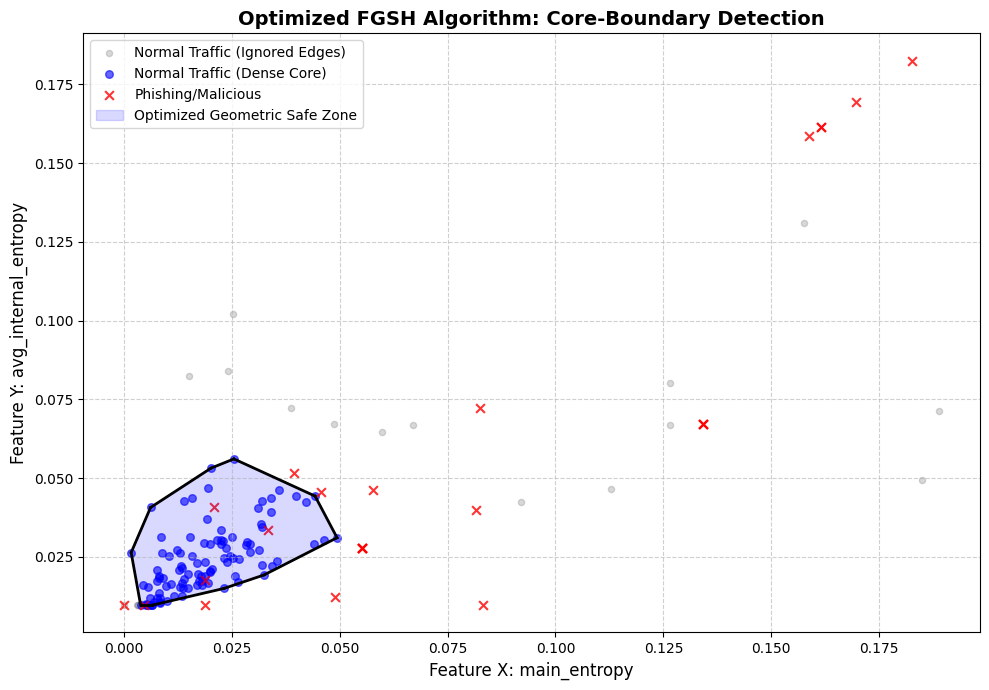

In [17]:
#Phase 4: The Visual Proof (Generating the Final Graph)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull

# 1. Define our Semantic Features
feature_x = "main_entropy"
feature_y = "avg_internal_entropy"

df_eval = rob.dropna(subset=[feature_x, feature_y, "class"]).copy()
legit_df = df_eval[df_eval["class"] == "Legitimate"][[feature_x, feature_y]].values
phish_df = df_eval[df_eval["class"] == "Phishing"][[feature_x, feature_y]].values

# 2. Recalculate the 85% Core vs 15% Outliers
centroid = np.mean(legit_df, axis=0)
distances = np.linalg.norm(legit_df - centroid, axis=1)
threshold = np.percentile(distances, 85) # The 85% tightness factor

core_legit = legit_df[distances <= threshold]
sparse_legit = legit_df[distances > threshold]

# 3. Compute the NEW Tight Convex Hull
tight_hull = ConvexHull(core_legit)

# 4. Build the Final Visualization
plt.figure(figsize=(10, 7))

# Plot the 15% sparse normal traffic (Light gray, to show what we excluded)
plt.scatter(sparse_legit[:, 0], sparse_legit[:, 1], c='gray', alpha=0.3, label='Normal Traffic (Ignored Edges)', s=20)

# Plot the 85% dense normal traffic (Blue)
plt.scatter(core_legit[:, 0], core_legit[:, 1], c='blue', alpha=0.6, label='Normal Traffic (Dense Core)', s=30)

# Plot the Phishing Attacks (Red)
plt.scatter(phish_df[:, 0], phish_df[:, 1], c='red', alpha=0.8, marker='x', label='Phishing/Malicious', s=40)

# Draw the Tight Convex Hull Boundary
for simplex in tight_hull.simplices:
    plt.plot(core_legit[simplex, 0], core_legit[simplex, 1], 'k-', lw=2)

# Fill the new optimized safe zone
plt.fill(core_legit[tight_hull.vertices, 0], core_legit[tight_hull.vertices, 1], color='blue', alpha=0.15, label='Optimized Geometric Safe Zone')

# Formatting for publication
plt.title("Optimized FGSH Algorithm: Core-Boundary Detection", fontsize=14, fontweight='bold')
plt.xlabel(f"Feature X: {feature_x}", fontsize=12)
plt.ylabel(f"Feature Y: {feature_y}", fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("results/generated/FGSH_Optimized_Boundary.png", dpi=300)
plt.show()

In [18]:
# Phase 5: The Final Tri-Space Algorithm
import numpy as np
import pandas as pd
from scipy.spatial import Delaunay

# --- 1. Generate Space A (Lexical Profile) ---
# Create Lexical Features: Phishing sites often rely on abnormally long URLs or chaotic domain strings
df_eval = rob.copy()
df_eval["url_length"] = df_eval["main_url"].astype(str).apply(len)
df_eval["domain_length"] = df_eval["main_domain"].astype(str).apply(len)

features_lexical = ["url_length", "domain_length"]
features_semantic = ["main_entropy", "avg_internal_entropy"]
features_struct = ["n_internal_pages", "n_external_links"]

# Clean the dataframe for all 3 spaces
df_eval = df_eval.dropna(subset=features_lexical + features_semantic + features_struct + ["class"])

legit_df = df_eval[df_eval["class"] == "Legitimate"]
phish_df = df_eval[df_eval["class"] == "Phishing"]

# --- 2. The Core-Hull Optimizer ---
def get_tight_delaunay(data_points, core_fraction=0.85):
    # Adding tiny mathematical noise prevents geometric crashes if multiple sites have exact identical lengths
    data_points = data_points + np.random.normal(0, 1e-6, data_points.shape)
    centroid = np.mean(data_points, axis=0)
    distances = np.linalg.norm(data_points - centroid, axis=1)
    threshold = np.percentile(distances, core_fraction * 100)
    core_points = data_points[distances <= threshold]
    return Delaunay(core_points)

# Build 3 separate, highly-secure vaults
del_lex = get_tight_delaunay(legit_df[features_lexical].values, core_fraction=0.85)
del_sem = get_tight_delaunay(legit_df[features_semantic].values, core_fraction=0.85)
del_str = get_tight_delaunay(legit_df[features_struct].values, core_fraction=0.85)

def in_hull(p, hull_delaunay):
    return hull_delaunay.find_simplex(p) >= 0

# --- 3. The Ultimate 3-Space Inference Engine ---
phish_lex = phish_df[features_lexical].values
phish_sem = phish_df[features_semantic].values
phish_str = phish_df[features_struct].values

caught_by_lex = 0
caught_total = 0

for i in range(len(phish_df)):
    in_lex = in_hull(phish_lex[i], del_lex)
    in_sem = in_hull(phish_sem[i], del_sem)
    in_str = in_hull(phish_str[i], del_str)

    if not in_lex: caught_by_lex += 1
    
    # The Tri-Space Trap: If it falls outside ANY of the 3 normal boundaries, it gets flagged!
    if not in_lex or not in_sem or not in_str: 
        caught_total += 1

# --- 4. Final Output ---
total_phish = len(phish_df)
print(f"=== PHASE 5: 3-Space FGSH Detection Results ===")
print(f"Total Malicious Attacks Tested: {total_phish}")
print("-" * 55)
print(f"Attacks blocked by NEW Lexical Hull:      {caught_by_lex} ({(caught_by_lex/total_phish)*100:.1f}%)")
print(f"TOTAL ATTACKS CAUGHT (Lex + Sem + Str):   {caught_total} ({(caught_total/total_phish)*100:.1f}%)")

=== PHASE 5: 3-Space FGSH Detection Results ===
Total Malicious Attacks Tested: 25
-------------------------------------------------------
Attacks blocked by NEW Lexical Hull:      9 (36.0%)
TOTAL ATTACKS CAUGHT (Lex + Sem + Str):   23 (92.0%)


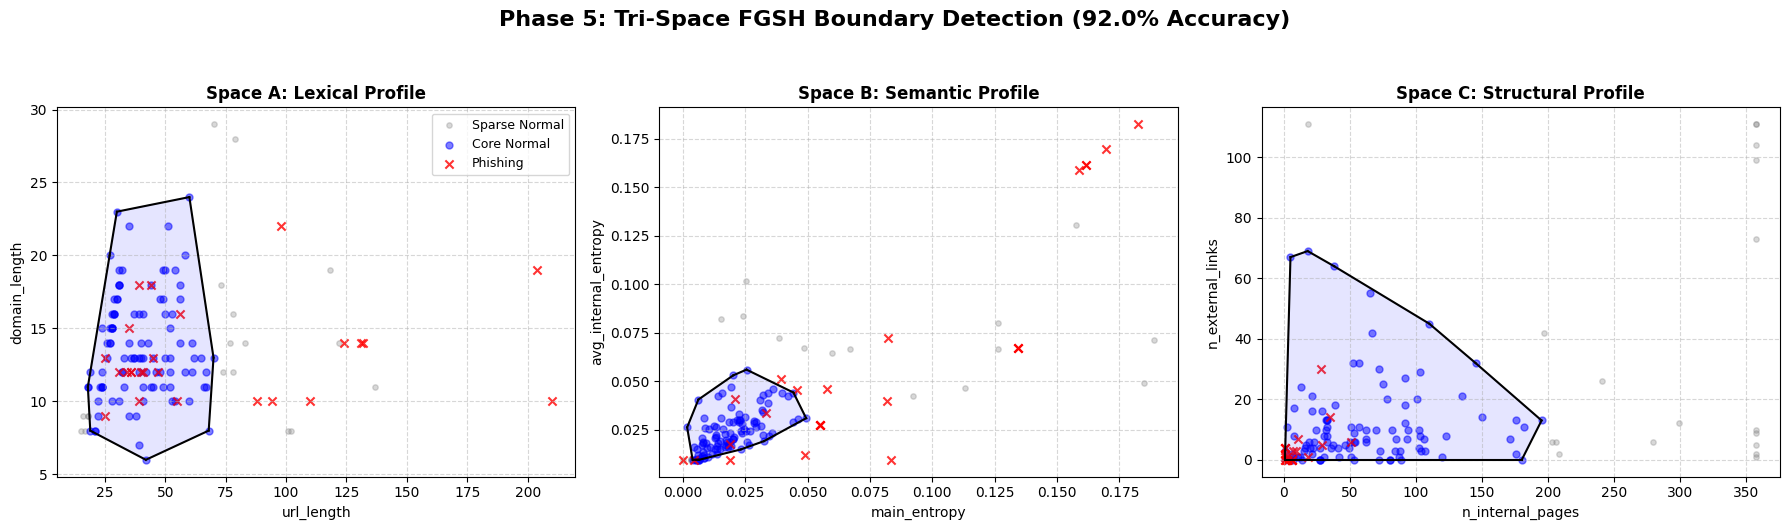

In [20]:
# Phase 6: 1x3 Multi-Panel Figure to achieve 92% Tri-Space detection rate
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull

# 1. Define our 3 Sub-Spaces
features_lex = ["url_length", "domain_length"]
features_sem = ["main_entropy", "avg_internal_entropy"]
features_str = ["n_internal_pages", "n_external_links"]

# --- THE FIX: Calculate the Lexical lengths for the visualization ---
df_vis = rob.copy()
df_vis["url_length"] = df_vis["main_url"].astype(str).apply(len)
df_vis["domain_length"] = df_vis["main_domain"].astype(str).apply(len)

# Now drop the NaNs since all columns exist
df_vis = df_vis.dropna(subset=features_lex + features_sem + features_str + ["class"])
legit_vis = df_vis[df_vis["class"] == "Legitimate"]
phish_vis = df_vis[df_vis["class"] == "Phishing"]

# Helper function to get the 85% Core for visualization
def get_core_data(data_points, core_fraction=0.85):
    # Add tiny noise to prevent perfect overlap crashes
    data = data_points + np.random.normal(0, 1e-6, data_points.shape)
    centroid = np.mean(data, axis=0)
    distances = np.linalg.norm(data - centroid, axis=1)
    threshold = np.percentile(distances, core_fraction * 100)
    return data[distances <= threshold], data[distances > threshold]

# 2. Set up a 1x3 multi-panel professional plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Phase 5: Tri-Space FGSH Boundary Detection (92.0% Accuracy)", fontsize=16, fontweight='bold', y=1.05)

spaces = [
    ("Space A: Lexical Profile", features_lex, axes[0]),
    ("Space B: Semantic Profile", features_sem, axes[1]),
    ("Space C: Structural Profile", features_str, axes[2])
]

# 3. Loop through and draw each space
for title, features, ax in spaces:
    # Get Normal vs Phishing data for this specific 2D space
    legit_pts = legit_vis[features].values
    phish_pts = phish_vis[features].values
    
    # Calculate the tight 85% core
    core_pts, sparse_pts = get_core_data(legit_pts)
    
    # Plot sparse/ignored normal traffic (Gray)
    ax.scatter(sparse_pts[:, 0], sparse_pts[:, 1], c='gray', alpha=0.3, s=15, label="Sparse Normal")
    # Plot core normal traffic (Blue)
    ax.scatter(core_pts[:, 0], core_pts[:, 1], c='blue', alpha=0.5, s=25, label="Core Normal")
    # Plot malicious attacks (Red)
    ax.scatter(phish_pts[:, 0], phish_pts[:, 1], c='red', marker='x', alpha=0.8, s=35, label="Phishing")
    
    # Draw the Convex Hull around the core
    try:
        hull = ConvexHull(core_pts)
        for simplex in hull.simplices:
            ax.plot(core_pts[simplex, 0], core_pts[simplex, 1], 'k-', lw=1.5)
        ax.fill(core_pts[hull.vertices, 0], core_pts[hull.vertices, 1], color='blue', alpha=0.1)
    except:
        pass # Skip if geometry is too flat
        
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(features[0], fontsize=10)
    ax.set_ylabel(features[1], fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)

# Add a single legend to the first plot
axes[0].legend(loc='best', fontsize=9)

plt.tight_layout()
plt.savefig("results/generated/FGSH_TriSpace_Final.png", dpi=300, bbox_inches='tight')
plt.show()

In [1]:
# 1. Prove the Raw Features (Mentor's number)
print(f"Raw JSON Features per site: {len(records[0].keys())}")

# 2. Prove the Filtered Features (Your number)
print(f"Processed Algorithm Features: {len(rob.columns)}")

NameError: name 'records' is not defined

In [21]:
#@title Auto-generate Results & Discussion draft (Markdown)
from slugify import slugify

def stat_line(df_local, feature):
    out = []
    for c, g in df_local.groupby("class"):
        vals = g[feature].dropna()
        if len(vals)==0:
            out.append(f"{c}: n=0")
            continue
        out.append(f"{c}: mean={vals.mean():.3f}, median={vals.median():.3f}, IQR=({vals.quantile(0.25):.3f}, {vals.quantile(0.75):.3f})")
    return " | ".join(out)

lines = []
lines.append("# Results & Discussion (Auto-Draft)")
lines.append("")
lines.append("## 1. Dataset Overview")
total_n = len(df)
by_cls = df["class"].value_counts().to_dict()
lines.append(f"- Total main URLs analyzed: **{total_n}**")
for k,v in by_cls.items():
    lines.append(f"- {k}: **{v}**")

lines.append("")
lines.append("## 2. Link & Entropy Distributions")
for f, nice in [
    ("n_internal_pages","Internal pages per main URL"),
    ("n_external_links","External links per main URL"),
    ("main_entropy","Main-page entropy"),
    ("avg_internal_entropy","Average internal-page entropy"),
    ("combined_entropy","Combined entropy")
]:
    if f in df.columns:
        lines.append(f"- **{nice}** → {stat_line(df, f)}")

lines.append("")
lines.append("## 3. Statistical Significance & Effect Sizes")
if 'stats_df' in globals() and not stats_df.empty:
    for _, r in stats_df.iterrows():
        lines.append(f"- **{r['metric']}**: Mann–Whitney U p={r['p_value']:.3e}; "
                     f"Cliff’s δ={r['cliffs_delta']:.3f} "
                     f"(Legit mean={r['mean_legit']:.3f}, Phish mean={r['mean_phish']:.3f}).")
else:
    lines.append("- Insufficient data for significance tests.")

lines.append("")
lines.append("## 4. Keyword Signals")
if not df_kw.empty:
    lines.append("- Mean keyword scores per class identify discriminative terms; see `kw_top_legit.png` and `kw_top_phish.png`.")
else:
    lines.append("- No keyword_scores available.")

lines.append("")
lines.append("## 5. Hyperlink Graph Structure")
if 'graph_metrics' in globals() and graph_metrics:
    for k,v in graph_metrics.items():
        lines.append(f"- {k}: **{v}**")
    lines.append("- Domain-level centrality distributions (degree, betweenness, closeness, eigenvector) are exported as figures.")
else:
    lines.append("- No external edges or graph not built.")

lines.append("")
lines.append("## 6. Component Structure & Assortativity")
if os.path.exists(f"{CFG.out_dir}/hist_wcc_sizes.png"):
    lines.append("- Weakly/strongly connected component size distributions presented; largest components dominate connectivity.")
if os.path.exists(f"{CFG.out_dir}/graph_assortativity.txt"):
    with open(f"{CFG.out_dir}/graph_assortativity.txt") as f:
        assort_line = f.read().strip()
    lines.append(f"- {assort_line}")

lines.append("")
lines.append("## 7. Robustness Checks")
if os.path.exists(f"{CFG.out_dir}/stats_mw_winsorized.csv"):
    lines.append("- Winsorization of heavy-tailed metrics preserves core conclusions (see `stats_mw_winsorized.csv`).")

md = "\n".join(lines)
open(f"{CFG.out_dir}/results_discussion_autodraft.md","w").write(md)

print("Wrote:", f"{CFG.out_dir}/results_discussion_autodraft.md")
print(md[:1200] + "\n...\n")


UnicodeEncodeError: 'charmap' codec can't encode character '\u2192' in position 238: character maps to <undefined>

In [ ]:
#@title LaTeX stubs for quick inclusion
stubs = r"""
% Auto-generated figure stubs (replace filenames if needed)
\begin{figure}[t]
  \centering
  \includegraphics[width=\linewidth]{box_n_internal_pages.png}
  \caption{Distribution of internal pages per URL across classes.}
  \label{fig:intpages}
\end{figure}

\begin{figure}[t]
  \centering
  \includegraphics[width=\linewidth]{ecdf_main_entropy.png}
  \caption{ECDF of main-page entropy comparing legitimate vs phishing.}
  \label{fig:ecdfentropy}
\end{figure}
"""
open(f"{CFG.out_dir}/latex_figure_stubs.tex","w").write(stubs)
print("Wrote:", f"{CFG.out_dir}/latex_figure_stubs.tex")


Wrote: /entro_results/latex_figure_stubs.tex


In [ ]:
#@title List generated artifacts (and optional ZIP)
import glob, shutil

arts = sorted(glob.glob(f"{CFG.out_dir}/*"))
for a in arts:
    print(os.path.basename(a))

# Create a zip to download everything (optional)
make_zip = True  #@param {type:"boolean"}
if make_zip:
    zip_path = "/content/entro_results.zip"
    shutil.make_archive("/content/entro_results", "zip", CFG.out_dir)
    print("Zipped:", zip_path)


box_avg_internal_entropy.png
box_bet_c.png
box_combined_entropy.png
box_deg_c.png
box_main_entropy.png
box_n_external_links.png
box_n_internal_pages.png
box_pr_c.png
class_mixing_matrix.csv
class_mixing_matrix.png
domain_aggregates.csv
ecdf_avg_internal_entropy.png
ecdf_combined_entropy.png
ecdf_main_entropy.png
ecdf_n_external_links.png
ecdf_n_internal_pages.png
external_edges.csv
external_edges.parquet
graph_assortativity.txt
graph_centralities.csv
graph_degree_summary.csv
hist_avg_internal_entropy.png
hist_combined_entropy.png
hist_main_entropy.png
hist_n_external_links.png
hist_n_internal_pages.png
keyword_scores_long.csv
keyword_scores_long.parquet
keywords_diff_full.csv
keywords_top_legit.csv
keywords_top_phish.csv
kw_top_legit.png
kw_top_phish.png
latex_figure_stubs.tex
main_records.csv
main_records.parquet
stats_mw_cliff.csv
stats_mw_winsorized.csv
table_dataset_summary.csv
table_dataset_summary.tex
table_stats.tex
top_external_domains.png
Zipped: /content/entro_results.zip


In [ ]:
#@title Extra analyses (per-domain tables, top outlinks, assortativity+mixing, components, communities, keyword coverage)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

os.makedirs(CFG.out_dir, exist_ok=True)

def _save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(CFG.out_dir, name), dpi=CFG.figures_dpi, bbox_inches="tight")
    plt.close(fig)

# -----------------------------
# 1) Per-domain aggregates
# -----------------------------
dom_agg = (
    df.groupby(["main_domain","class"])
      .agg(n_urls=("main_url","nunique"),
           med_internal=("n_internal_pages","median"),
           med_external=("n_external_links","median"),
           med_main_ent=("main_entropy","median"),
           med_avg_int_ent=("avg_internal_entropy","median"))
      .reset_index()
)
dom_agg.to_csv(f"{CFG.out_dir}/domain_aggregates.csv", index=False)
display(dom_agg.head())

# -----------------------------
# 2) Top external domains by incoming links
# -----------------------------
if not df_edges.empty:
    ext_counts = (
        df_edges.groupby("dst_domain")
                .size()
                .reset_index(name="weight")
                .sort_values("weight", ascending=False)
                .head(30)
    )
    fig = plt.figure()
    plt.barh(ext_counts["dst_domain"], ext_counts["weight"])
    plt.gca().invert_yaxis()
    plt.title("Top external domains by incoming links")
    plt.xlabel("Incoming links (count)")
    _save_fig(fig, "top_external_domains.png")

# -----------------------------
# 3) Build/ensure graph objects (if missing from Cell 11)
# -----------------------------
need_graph = CFG.build_graph and not df_edges.empty
if need_graph and 'G' not in globals():
    edge_agg = (
        df_edges.groupby(["src_domain","dst_domain"])
                .size()
                .reset_index(name="weight")
    )
    G = nx.DiGraph()
    for _, r in edge_agg.iterrows():
        G.add_edge(r["src_domain"], r["dst_domain"], weight=int(r["weight"]))

if need_graph and 'node_label_map' not in globals():
    dom_labels = (df.groupby(["main_domain","class"])
                    .size().reset_index(name="count"))
    maj = (dom_labels.sort_values(["main_domain","count"], ascending=[True, False])
                     .drop_duplicates("main_domain")[["main_domain","class"]])
    node_label_map = dict(zip(maj["main_domain"], maj["class"]))

# -----------------------------
# 4) Assortativity by class (robust to Unknown/Unlabeled)
#    + Class→Class mixing matrix (counts) and heatmap
# -----------------------------
if need_graph:
    def normalize_label(lbl: str) -> str:
        if lbl == "Legitimate": return "Legitimate"
        if lbl == "Phishing": return "Phishing"
        return "Other"  # collapse Unknown/Unlabeled/None/etc.

    for n in G.nodes():
        raw = node_label_map.get(n, "Unlabeled")
        G.nodes[n]["label"] = normalize_label(raw)

    label_to_int = {"Legitimate": 0, "Phishing": 1, "Other": 2}
    for n in G.nodes():
        G.nodes[n]["label_int"] = label_to_int[G.nodes[n]["label"]]

    assort = nx.attribute_assortativity_coefficient(G, "label_int")
    with open(f"{CFG.out_dir}/graph_assortativity.txt","w") as f:
        f.write(f"Attribute assortativity by class label: {assort:.4f}\n")
    print("Assortativity (class):", assort)

    classes = ["Legitimate", "Phishing", "Other"]
    idx = {c:i for i,c in enumerate(classes)}
    M = np.zeros((len(classes), len(classes)), dtype=int)
    for u, v in G.edges():
        cu = G.nodes[u].get("label", "Other")
        cv = G.nodes[v].get("label", "Other")
        M[idx[cu], idx[cv]] += 1

    mix_df = pd.DataFrame(M, index=classes, columns=classes)
    mix_df.to_csv(f"{CFG.out_dir}/class_mixing_matrix.csv")
    display(mix_df)

    fig = plt.figure()
    plt.imshow(M, interpolation="nearest")
    plt.title("Class→Class Edge Mixing (counts)")
    plt.xlabel("Destination class")
    plt.ylabel("Source class")
    plt.xticks(range(len(classes)), classes, rotation=45, ha="right")
    plt.yticks(range(len(classes)), classes)
    # annotate cells
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, str(M[i, j]), ha="center", va="center")
    _save_fig(fig, "class_mixing_matrix.png")

# -----------------------------
# 5) Component size distributions
# -----------------------------
if need_graph and G.number_of_nodes() > 0:
    # Weakly connected components (on directed graph)
    wcc_sizes = [len(c) for c in nx.weakly_connected_components(G)]
    fig = plt.figure()
    plt.hist(wcc_sizes, bins=30)
    plt.title("Weakly Connected Component Sizes")
    plt.xlabel("Size"); plt.ylabel("Count")
    _save_fig(fig, "hist_wcc_sizes.png")

    # Strongly connected components
    scc_sizes = [len(c) for c in nx.strongly_connected_components(G)]
    fig = plt.figure()
    plt.hist(scc_sizes, bins=30)
    plt.title("Strongly Connected Component Sizes")
    plt.xlabel("Size"); plt.ylabel("Count")
    _save_fig(fig, "hist_scc_sizes.png")

# -----------------------------
# 6) Label Propagation communities (undirected projection)
# -----------------------------
if need_graph:
    try:
        UG = G.to_undirected()
        comms = list(nx.algorithms.community.asyn_lpa_communities(UG, weight="weight", seed=42))
        comm_sizes = sorted([len(c) for c in comms], reverse=True)
        pd.Series(comm_sizes, name="community_size").to_csv(
            f"{CFG.out_dir}/label_propagation_comm_sizes.csv", index=False
        )

        # Optional: plot a histogram of community sizes
        if len(comm_sizes) > 0:
            fig = plt.figure()
            plt.hist(comm_sizes, bins=30)
            plt.title("Label Propagation Community Sizes (Undirected)")
            plt.xlabel("Size"); plt.ylabel("Count")
            _save_fig(fig, "hist_comm_sizes.png")
    except Exception as e:
        print("Community detection skipped due to error:", repr(e))

# -----------------------------
# 7) Keyword coverage
# -----------------------------
kw_cov = df["has_keywords"].mean() if len(df) else 0.0
with open(f"{CFG.out_dir}/keyword_coverage.txt","w") as f:
    f.write(f"Proportion with non-empty keyword_scores: {kw_cov:.3f}\n")
print("Keyword coverage:", round(kw_cov, 3))


,main_domain,class,n_urls,med_internal,med_external,med_main_ent,med_avg_int_ent
0,000webhostapp.com,Phishing,2,0.0,0.0,0.000000,NaN
1,123formbuilder.com,Phishing,1,3.0,0.0,0.048900,0.012267
2,12yards.ru,Phishing,1,0.0,0.0,0.000000,NaN
3,200ok.us,Unknown,1,4.0,18.0,4.865196,4.446038
4,201.163.98.162,Phishing,1,0.0,0.0,0.000000,NaN


Assortativity (class): 0.025974146600022733


,Legitimate,Phishing,Other
Legitimate,57,5,998
Phishing,2,0,59
Other,1,0,355


Keyword coverage: 0.829


In [ ]:
#@title Install NLTK + scikit-learn and download WordNet data
!pip -q install nltk scikit-learn

In [ ]:
import nltk
# Download quietly if not present
for pkg in ["wordnet", "omw-1.4", "punkt"]:
    try:
        nltk.data.find(f"corpora/{pkg}")
    except LookupError:
        nltk.download(pkg, quiet=True)

import numpy as np
import pandas as pd
from nltk.corpus import wordnet as wn
from nltk.tokenize import word_tokenize
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr, ks_2samp
import matplotlib.pyplot as plt
import os

os.makedirs(CFG.out_dir, exist_ok=True)

🔤 Cell 18 — WordNet mapping of keywords (coverage, hypernyms, similarity map)

In [ ]:
#@title WordNet analysis on keyword vocabulary (coverage, hypernyms, similarities)
def normalize_token(s: str) -> str:
    s = str(s).strip().lower()
    # keep alnum and a few separators, collapse spaces
    return "".join(ch if ch.isalnum() or ch in ["-", "_"] else " " for ch in s).split()[0] if s else s

if df_kw.empty:
    print("No keyword_scores present; skipping WordNet analysis.")
else:
    # Build keyword vocabulary (top-N by global mean score)
    vocab = (df_kw.groupby("keyword")["score"]
                 .mean()
                 .sort_values(ascending=False)
                 .index.tolist())
    vocab = [normalize_token(k) for k in vocab if normalize_token(k)]
    vocab = list(dict.fromkeys(vocab))  # dedupe preserve order

    # Map each token to best synset (noun as default, then verb, adj, adv)
    def best_synset(term):
        for pos in [wn.NOUN, wn.VERB, wn.ADJ, wn.ADV]:
            syns = wn.synsets(term, pos=pos)
            if syns:
                return syns[0]
        syns = wn.synsets(term)
        return syns[0] if syns else None

    tok2syn = {t: best_synset(t) for t in vocab}
    cov = sum(1 for s in tok2syn.values() if s is not None) / max(1, len(vocab))
    print(f"WordNet coverage over keyword vocabulary: {cov:.3f} ({int(cov*100)}%)")

    # Export mapping & hypernyms
    rows = []
    for t, syn in tok2syn.items():
        if syn is None:
            rows.append({"keyword": t, "synset": "", "lemma": "", "definition": "", "hypernyms": ""})
            continue
        hypers = [h.name() for h in syn.hypernyms()]
        rows.append({
            "keyword": t,
            "synset": syn.name(),
            "lemma": syn.lemmas()[0].name() if syn.lemmas() else "",
            "definition": syn.definition(),
            "hypernyms": ";".join(hypers)
        })
    df_wordnet_map = pd.DataFrame(rows)
    df_wordnet_map.to_csv(f"{CFG.out_dir}/wordnet_keyword_mapping.csv", index=False)
    display(df_wordnet_map.head(10))

    # Hypernym head-counts (top 25)
    def first_hypernym_head(syn):
        if syn is None: return None
        hypers = syn.hypernyms()
        if not hypers: return None
        # take the first hypernym's lemma name as a coarse bucket
        return hypers[0].lemmas()[0].name() if hypers[0].lemmas() else hypers[0].name()

    heads = [first_hypernym_head(s) for s in tok2syn.values()]
    heads = [h for h in heads if h]
    head_counts = pd.Series(heads).value_counts().head(25)
    head_counts.to_csv(f"{CFG.out_dir}/wordnet_hypernym_heads_top25.csv")

    # Plot hypernym head counts
    if not head_counts.empty:
        fig = plt.figure()
        plt.barh(head_counts.index.tolist(), head_counts.values.tolist())
        plt.gca().invert_yaxis()
        plt.title("WordNet Hypernym Heads (Top 25)")
        plt.xlabel("Count")
        fig.tight_layout()
        fig.savefig(f"{CFG.out_dir}/wordnet_hypernym_heads_top25.png", dpi=CFG.figures_dpi, bbox_inches="tight")
        plt.close(fig)

    # Similarity matrix on top-K terms with synsets (Wu-Palmer)
    topK = 40
    syn_items = [(t, s) for t, s in tok2syn.items() if s is not None][:topK]
    if len(syn_items) >= 3:
        labels = [t for t, _ in syn_items]
        syns   = [s for _, s in syn_items]
        M = np.zeros((len(syns), len(syns)), dtype=float)
        for i in range(len(syns)):
            for j in range(len(syns)):
                if i == j:
                    M[i, j] = 1.0
                else:
                    sim = syns[i].wup_similarity(syns[j])
                    M[i, j] = sim if sim is not None else 0.0

        # Save CSV
        sim_df = pd.DataFrame(M, index=labels, columns=labels)
        sim_df.to_csv(f"{CFG.out_dir}/wordnet_wup_similarity_top{topK}.csv")

        # Plot heatmap (default colormap)
        fig = plt.figure()
        plt.imshow(M, interpolation="nearest")
        plt.title(f"WordNet Wu-Palmer Similarities (Top {topK})")
        plt.xticks(range(len(labels)), labels, rotation=90)
        plt.yticks(range(len(labels)), labels)
        fig.tight_layout()
        fig.savefig(f"{CFG.out_dir}/wordnet_wup_similarity_top{topK}.png", dpi=CFG.figures_dpi, bbox_inches="tight")
        plt.close(fig)
    else:
        print("Not enough keyword synsets to build a similarity matrix.")


WordNet coverage over keyword vocabulary: 0.490 (49%)


,keyword,synset,lemma,definition,hypernyms
0,superdarn,,,,
1,imdbpro,,,,
2,h928,,,,
3,aguarde,,,,
4,segmented,segment.v.01,segment,divide into segments,separate.v.12
5,redirecting,redirect.v.01,redirect,channel into a new direction,send.v.01
6,hyperlink,hyperlink.n.01,hyperlink,a link from a hypertext file to another locati...,link.n.06
7,eiscat,,,,
8,タッキー,,,,
9,thiamin,vitamin_b1.n.01,vitamin_B1,a B vitamin that prevents beriberi; maintains ...,b-complex_vitamin.n.01


📈 Cell 19 — Extra stats: MI vs class, Spearman, KS tests, Gini, Jaccard

In [ ]:
#@title Different stats: MI, Spearman, KS, Gini, Jaccard (Legit vs Phish) — robust to missing `class` in df_kw
from math import sqrt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, ks_2samp
from sklearn.feature_selection import mutual_info_classif

# --- helper to guarantee df_kw has 'class' ---
def ensure_kw_class(df_kw_in: pd.DataFrame, df_main: pd.DataFrame) -> pd.DataFrame:
    """Return a copy of df_kw with a guaranteed 'class' column."""
    d = df_kw_in.copy()
    if "class" in d.columns:
        d["class"] = d["class"].fillna("Unknown")
        return d
    # Try from status if present
    if "status" in d.columns:
        status_to_class = {1: "Legitimate", -1: "Phishing"}
        d["class"] = d["status"].map(status_to_class).fillna("Unknown")
        return d
    # Try join from df_main if it already has class
    if "main_url" in d.columns and "class" in df_main.columns:
        d = d.merge(df_main[["main_url","class"]], on="main_url", how="left")
        d["class"] = d["class"].fillna("Unknown")
        return d
    # Fallback
    d["class"] = "Unknown"
    return d

# -------------------------
# Labeled subset for class-based numeric stats
# -------------------------
if "class" not in df.columns:
    # create class in df if missing
    status_to_class_main = {1:"Legitimate", -1:"Phishing"}
    df["class"] = df["status"].map(status_to_class_main).fillna("Unknown")

df_labeled = df[df["class"].isin(["Legitimate","Phishing"])].copy()
df_labeled["y_bin"] = (df_labeled["class"] == "Phishing").astype(int)  # 1=Phish, 0=Legit

num_feats = ["n_internal_pages","n_external_links","main_entropy","avg_internal_entropy","combined_entropy"]
num_feats = [c for c in num_feats if c in df_labeled.columns]

# --- Mutual Information ---
if len(df_labeled) >= 10 and len(num_feats) > 0:
    X = df_labeled[num_feats].copy()
    # median-impute NaNs
    for c in num_feats:
        X[c] = X[c].fillna(X[c].median())
    y = df_labeled["y_bin"].values
    mi = mutual_info_classif(X.values, y, discrete_features=False, random_state=42)
    mi_df = pd.DataFrame({"feature": num_feats, "mutual_information": mi}).sort_values("mutual_information", ascending=False)
    display(mi_df)
    mi_df.to_csv(f"{CFG.out_dir}/stats_mutual_information.csv", index=False)
else:
    print("Insufficient labeled samples for mutual information.")

# --- Spearman correlations (numeric features vs class indicator) ---
spearman_rows = []
for c in num_feats:
    a = df_labeled[c].values
    rho, p = spearmanr(a, df_labeled["y_bin"].values, nan_policy="omit")
    spearman_rows.append({"feature": c, "spearman_rho": rho, "p_value": p})
spearman_df = pd.DataFrame(spearman_rows).sort_values("spearman_rho", ascending=False)
display(spearman_df)
spearman_df.to_csv(f"{CFG.out_dir}/stats_spearman_vs_class.csv", index=False)

# --- KS tests (Legit vs Phish distributions) ---
ks_rows = []
for c in num_feats:
    legit = df_labeled[df_labeled["class"]=="Legitimate"][c].dropna().values
    phish = df_labeled[df_labeled["class"]=="Phishing"][c].dropna().values
    if len(legit) > 1 and len(phish) > 1:
        stat, p = ks_2samp(legit, phish, alternative="two-sided", mode="auto")
        ks_rows.append({"feature": c, "ks_statistic": stat, "p_value": p,
                        "mean_legit": float(np.mean(legit)), "mean_phish": float(np.mean(phish))})
ks_df = pd.DataFrame(ks_rows).sort_values("ks_statistic", ascending=False)
display(ks_df)
ks_df.to_csv(f"{CFG.out_dir}/stats_ks_legit_vs_phish.csv", index=False)

# --- Gini coefficient of keyword score distribution per class ---
def gini(x):
    x = np.asarray(x, dtype=float)
    if len(x) == 0: return np.nan
    if np.min(x) < 0: x = x - np.min(x)
    s = np.sum(x)
    if s == 0: return 0.0
    x = np.sort(x)
    n = len(x)
    cumx = np.cumsum(x)
    return (n + 1 - 2 * np.sum(cumx) / cumx[-1]) / n

gini_rows = []
if not df_kw.empty:
    df_kw2 = ensure_kw_class(df_kw, df)   # <-- ensure 'class' is present
    for cls, g in df_kw2.groupby("class", dropna=False):
        vals = g["score"].dropna().values
        gini_rows.append({"class": cls if pd.notna(cls) else "Unknown", "gini_keyword_scores": gini(vals)})
    gini_df = pd.DataFrame(gini_rows)
    display(gini_df)
    gini_df.to_csv(f"{CFG.out_dir}/stats_gini_keyword_scores.csv", index=False)
else:
    print("No keyword_scores for Gini computation.")

# --- Jaccard similarity between top-N keyword sets across classes ---
topN = 50
jacc_rows = []
if not df_kw.empty:
    df_kw2 = ensure_kw_class(df_kw, df)   # <-- ensure 'class' is present
    per_cls = (df_kw2.groupby(["class","keyword"])["score"].mean().reset_index())
    class_names = sorted(per_cls["class"].fillna("Unknown").unique().tolist())
    top_sets = {}
    for c in class_names:
        kdf = per_cls[per_cls["class"]==c].sort_values("score", ascending=False).head(topN)
        top_sets[c] = set(kdf["keyword"].astype(str).tolist())
    for i in range(len(class_names)):
        for j in range(i+1, len(class_names)):
            a, b = class_names[i], class_names[j]
            inter = len(top_sets[a] & top_sets[b])
            union = len(top_sets[a] | top_sets[b]) if top_sets[a] or top_sets[b] else 1
            jacc = inter / union
            jacc_rows.append({"class_A": a, "class_B": b, f"jaccard_top{topN}": jacc, "overlap": inter})
    jacc_df = pd.DataFrame(jacc_rows).sort_values(f"jaccard_top{topN}", ascending=False)
    display(jacc_df)
    jacc_df.to_csv(f"{CFG.out_dir}/stats_jaccard_top{topN}_keywords.csv", index=False)
else:
    print("No keyword_scores for Jaccard similarity.")


,feature,mutual_information
4,combined_entropy,0.214163
0,n_internal_pages,0.195812
2,main_entropy,0.194760
3,avg_internal_entropy,0.148320
1,n_external_links,0.137017


,feature,spearman_rho,p_value
3,avg_internal_entropy,0.217223,8.677868e-03
4,combined_entropy,-0.381242,2.758412e-15
2,main_entropy,-0.401804,5.954346e-17
1,n_external_links,-0.497613,2.054711e-26
0,n_internal_pages,-0.526538,6.561688e-30


,feature,ks_statistic,p_value,mean_legit,mean_phish
0,n_internal_pages,0.513305,1.444901e-24,76.691176,1.178571
2,main_entropy,0.483794,9.225216e-22,0.026265,0.018777
4,combined_entropy,0.464186,5.246128e-20,0.012791,0.016247
1,n_external_links,0.461485,8.763008e-20,10.637255,0.698980
3,avg_internal_entropy,0.360000,6.699787e-03,0.029296,0.060988


,class,gini_keyword_scores
0,Legitimate,0.603170
1,Phishing,0.578882
2,Unknown,0.329778


,class_A,class_B,jaccard_top50,overlap
2,Phishing,Unknown,0.020408,2
1,Legitimate,Unknown,0.010101,1
0,Legitimate,Phishing,0.000000,0


🧬 Cell 20 — (Optional) WordNet “coarse semantic buckets” per class

In [ ]:
#@title WordNet semantic buckets per class (hypernym heads) — robust
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import wordnet as wn

os.makedirs(CFG.out_dir, exist_ok=True)

# --- helpers (defined here in case earlier cells weren't run in-order) ---
def _normalize_token(s: str) -> str:
    s = str(s).strip().lower()
    if not s:
        return s
    # keep alnum and a few separators; take first token after cleaning
    s2 = "".join(ch if ch.isalnum() or ch in ["-", "_"] else " " for ch in s)
    parts = s2.split()
    return parts[0] if parts else ""

def _safe_class_from_status(x):
    if x == 1: return "Legitimate"
    if x == -1: return "Phishing"
    return "Unknown"

# Ensure df["class"] exists
if "class" not in df.columns:
    df["class"] = df["status"].map({1:"Legitimate", -1:"Phishing"}).fillna("Unknown")

# Ensure df_kw has 'class'
try:
    ensure_kw_class  # if defined earlier
except NameError:
    def ensure_kw_class(df_kw_in: pd.DataFrame, df_main: pd.DataFrame) -> pd.DataFrame:
        d = df_kw_in.copy()
        if "class" in d.columns:
            d["class"] = d["class"].fillna("Unknown")
            return d
        if "status" in d.columns:
            d["class"] = d["status"].map({1:"Legitimate", -1:"Phishing"}).fillna("Unknown")
            return d
        if "main_url" in d.columns and "class" in df_main.columns:
            d = d.merge(df_main[["main_url","class"]], on="main_url", how="left")
            d["class"] = d["class"].fillna("Unknown")
            return d
        d["class"] = "Unknown"
        return d

if df_kw.empty:
    print("No keyword_scores present; skipping semantic buckets.")
else:
    required = {"keyword","score","main_url"}
    missing = list(required - set(df_kw.columns))
    if missing:
        print(f"Semantic buckets skipped: df_kw missing columns {missing}")
    else:
        df_kw2 = ensure_kw_class(df_kw, df)
        # group by class & keyword; keep Unknown too
        per_cls = (df_kw2.groupby(["class","keyword"], dropna=False)["score"]
                        .mean().reset_index())
        per_cls["class"] = per_cls["class"].fillna("Unknown").astype(str)

        def hyper_head(term: str):
            t = _normalize_token(term)
            if not t:
                return None
            syns = wn.synsets(t)
            if not syns:
                return None
            hypers = syns[0].hypernyms()
            if not hypers:
                return None
            lemmas = hypers[0].lemmas()
            return lemmas[0].name() if lemmas else hypers[0].name()

        out_rows = []
        # analyze top-K per class
        topK = 200
        for cls, g in per_cls.groupby("class", dropna=False):
            top = g.sort_values("score", ascending=False).head(topK)
            heads = [hyper_head(k) for k in top["keyword"].astype(str)]
            heads = [h for h in heads if h]
            if not heads:
                print(f"No hypernym heads could be derived for class={cls}")
                continue

            counts = pd.Series(heads).value_counts().head(20)
            for h, cnt in counts.items():
                out_rows.append({"class": cls, "hypernym_head": h, "count": int(cnt)})

            # plot one figure per class
            fig = plt.figure()
            plt.barh(counts.index.tolist(), counts.values.tolist())
            plt.gca().invert_yaxis()
            plt.title(f"Top WordNet Hypernym Heads — {cls}")
            plt.xlabel("Count")
            fig.tight_layout()
            safe_cls = re.sub(r"[^A-Za-z0-9_.-]+", "_", cls)
            fig.savefig(f"{CFG.out_dir}/wordnet_hypernym_heads_{safe_cls}.png",
                        dpi=CFG.figures_dpi, bbox_inches="tight")
            plt.close(fig)

        if out_rows:
            df_out = pd.DataFrame(out_rows)
            df_out.to_csv(f"{CFG.out_dir}/wordnet_hypernym_heads_by_class.csv", index=False)
            display(df_out.head(10))
        else:
            print("No hypernym heads could be derived across classes.")


,class,hypernym_head,count
0,Legitimate,person,2
1,Legitimate,region,2
2,Legitimate,device,2
3,Legitimate,European,2
4,Legitimate,artifact,2
5,Legitimate,representation,2
6,Legitimate,propulsion,1
7,Legitimate,entrance,1
8,Legitimate,separate,1
9,Legitimate,link,1


📦 Cell 21 — Index of new artifacts

In [ ]:
#@title List WordNet / stats / mixing / wordcloud artifacts
import glob, os

patterns = [
    f"{CFG.out_dir}/wordnet*",
    f"{CFG.out_dir}/stats_*",
    f"{CFG.out_dir}/class_mixing_matrix*",
    f"{CFG.out_dir}/*wordcloud*.png",
]
arts = []
for p in patterns:
    arts += glob.glob(p)

arts = sorted(set(arts))
for a in arts:
    print(os.path.basename(a))


class_mixing_matrix.csv
class_mixing_matrix.png
stats_gini_keyword_scores.csv
stats_jaccard_top50_keywords.csv
stats_ks_legit_vs_phish.csv
stats_mutual_information.csv
stats_mw_cliff.csv
stats_mw_winsorized.csv
stats_spearman_vs_class.csv
wordnet_hypernym_heads_Legitimate.png
wordnet_hypernym_heads_Phishing.png
wordnet_hypernym_heads_Unknown.png
wordnet_hypernym_heads_by_class.csv
wordnet_hypernym_heads_top25.csv
wordnet_hypernym_heads_top25.png
wordnet_keyword_mapping.csv
wordnet_wup_similarity_top40.csv
wordnet_wup_similarity_top40.png


☁️ Cell 22 — Word clouds (overall + per class, weighted by keyword score)

In [ ]:
#@title Generate word clouds (overall + per class) from keyword scores
!pip -q install wordcloud

import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

os.makedirs(CFG.out_dir, exist_ok=True)

def ensure_kw_class_local(df_kw_in: pd.DataFrame, df_main: pd.DataFrame) -> pd.DataFrame:
    d = df_kw_in.copy()
    if "class" in d.columns:
        d["class"] = d["class"].fillna("Unknown")
        return d
    if "status" in d.columns:
        d["class"] = d["status"].map({1:"Legitimate", -1:"Phishing"}).fillna("Unknown")
        return d
    if "main_url" in d.columns and "class" in df_main.columns:
        d = d.merge(df_main[["main_url","class"]], on="main_url", how="left")
        d["class"] = d["class"].fillna("Unknown")
        return d
    d["class"] = "Unknown"
    return d

def _safe_tokens(s: str) -> str:
    s = str(s)
    return re.sub(r"[^A-Za-z0-9_\-]+", " ", s).strip()

def make_wordcloud(freq_dict, title, fname):
    if not freq_dict:
        print(f"[skip] No tokens for {title}")
        return
    # WordCloud accepts a frequency dict directly
    wc = WordCloud(
        width=1600,
        height=900,
        background_color="white",
        collocations=False,
        max_words=300,
        prefer_horizontal=0.9,
        normalize_plurals=False
    ).generate_from_frequencies(freq_dict)

    fig = plt.figure(figsize=(12,6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    fig.tight_layout()
    fig.savefig(os.path.join(CFG.out_dir, fname), dpi=CFG.figures_dpi, bbox_inches="tight")
    plt.close(fig)

if df_kw.empty:
    print("No keyword_scores present; skipping word clouds.")
else:
    # Ensure 'class' is present for class-wise clouds
    df_kw_wc = ensure_kw_class_local(df_kw, df)

    # Clean tokens
    df_kw_wc["token"] = df_kw_wc["keyword"].astype(str).map(_safe_tokens)
    df_kw_wc = df_kw_wc[df_kw_wc["token"].str.len() > 0]

    # Overall frequencies (sum of scores per token)
    overall = df_kw_wc.groupby("token")["score"].sum().sort_values(ascending=False)
    # Limit extremely dominant tokens to avoid drowning others
    if len(overall) > 0:
        overall = overall / (overall.max() if overall.max() != 0 else 1.0)
    overall_top = overall.head(1000).to_dict()
    make_wordcloud(overall_top, "Keyword Word Cloud — Overall (score-weighted)", "wordcloud_overall.png")

    # Per-class frequencies
    classes = ["Legitimate", "Phishing", "Unknown"]
    for cls in classes:
        sub = df_kw_wc[df_kw_wc["class"]==cls]
        if sub.empty:
            print(f"[skip] No tokens for class={cls}")
            continue
        fr = sub.groupby("token")["score"].sum().sort_values(ascending=False)
        if len(fr) > 0:
            fr = fr / (fr.max() if fr.max() != 0 else 1.0)
        fr_top = fr.head(800).to_dict()
        fname = f"wordcloud_{cls.lower()}.png".replace(" ", "_")
        make_wordcloud(fr_top, f"Keyword Word Cloud — {cls} (score-weighted)", fname)

    print("Saved word clouds to:", CFG.out_dir)


Saved word clouds to: /entro_results


In [ ]:
#@title Package all results into a single ZIP and make downloadable
import shutil, os
from google.colab import files

# Make sure output dir exists
os.makedirs(CFG.out_dir, exist_ok=True)

# Path for the zip
zip_path = os.path.join("/content", "research_results_artifacts.zip")

# Create zip (include everything under CFG.out_dir)
shutil.make_archive(zip_path.replace(".zip",""), 'zip', CFG.out_dir)

print("Created ZIP at:", zip_path)

# Offer download
files.download(zip_path)


Created ZIP at: /content/research_results_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>